# Drug-regulon associations from a common pooled reference

This notebook adds downstream analysis to the completed pySCENIC workflow.
It does **not** infer new TF-target networks or change existing Loom/AUC files.

**Design:** one drug dose and treatment window, d30 endpoint, DMSO control,
no biological replicates or batch/sample/organoid identifiers.

1. Validate and align cell-level pooled AUCell and Loom annotations.
2. Fit drug indicators -> regulon AUC, globally and within cell types.
3. Examine held-out prediction, repeat-run stability and matched Delta AUC.
4. Export edge/node tables, descriptive impact rankings and network figures.

The regression uses Arboreto's native GRNBoost2 GBM configuration, early-stop
monitor and importance calculation. It calls that regression core per regulon
instead of creating a Dask cluster, avoiding Dask worker-memory restarts.
The default backend is the existing pySCENIC Apptainer image.

**Interpretation:** importance is a prediction contribution, not activation,
a causal effect or a P value. Global associations include composition changes.
Within-cell-type analyses help inspect that distinction but cannot remove
unknown batch effects. Resampled cells are not biological replicates.
The held-out cells come from the same experiment: this is a technical check,
not evidence of out-of-organoid generalization. One-hot drug predictors cannot
learn concentration responses, and their importance is not a DMSO contrast.
The regulon reference was inferred from pooled data including these cells:
only the association regression is held out, not the complete SCENIC pipeline.

This follows the authors' association-model idea, adapted to binary drug
indicators rather than morphogen concentration/timing/interaction variables.
Default graphics use NetworkX spring layout, not the paper's R backbone layout.

Sources: [paper and methods](https://www.nature.com/articles/s41592-025-02927-5),
[authors' model](https://github.com/quadbio/organoid_patterning_screen/blob/main/scenic_runs/src/grnboost_analysis.py),
[Arboreto core](https://github.com/aertslab/arboreto/blob/master/arboreto/core.py).

## Environment and execution
Run the notebook kernel on an **allocated compute node**, not a login node.
The kernel only needs the packages below; pySCENIC/Arboreto run in Apptainer.
If needed, create a separate analysis environment in a terminal:

```bash
conda create -n drug_assoc -c conda-forge \
  python=3.11 numpy pandas h5py matplotlib networkx adjusttext pyyaml ipykernel
conda activate drug_assoc
python -m ipykernel install --user --name drug_assoc --display-name "Drug associations"
```

Select that kernel in VS Code. Keep the kernel/allocation alive during fitting.
Checkpoints permit resuming after interruption. Existing source results are
read-only; all new results go to `analysis/drug_regulon_association/`.

In [1]:
import csv
import hashlib
import json
import math
import os
import re
import shutil
import signal
import subprocess
import sys
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import pandas as pd
import yaml
from adjustText import adjust_text
from IPython.display import display

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10})

## 1. Parameters

`DRUGS_OVERRIDE=None` reads the pipeline's included-drug list, including DMSO.
`TRAINING_CAP_PER_DRUG=2000` is a clearly defined **model-training** cap, not
a new preprocessing filter. Balancing preserves each drug's observed cell-type
proportions in the global model. Set the cap to `None` to remove the cap;
`BALANCE_DRUGS=True` still uses the smallest eligible condition's cell count.
Set both cap=None and balance=False to train on all available cells.

The same policy is applied separately inside each cell type. Conditions with
fewer than 2 cells cannot enter that model and are recorded as unavailable,
**not zero importance**. Counts below 50 are warnings only, not a new filter.

Stability thresholds below are **exploratory display rules**, not significance
thresholds or the paper's `weight > 200`. At least two seeds are required.
All regulons, not selected top regulons, are used for model fitting and ranking.
Each selected training pool is split within drug into fit and held-out cells.
A displayed edge must pass the share threshold **and** its target model must
improve held-out MSE versus the constant training-mean predictor. These are
adjustable exploratory criteria, not a P-value or a new biological replicate.

In [2]:
PROJECT = Path("/home/jiafzhou/GRN_org")
CFG = {
    "project": str(PROJECT),
    "results_dir": str(PROJECT / "results"),
    "drug_list_file": str(PROJECT / "config/included_drugs.txt"),
    "regulons_file": str(PROJECT / "results/_pooled_reference_allcells/pooled_regulons.csv"),
    "image": str(PROJECT / "container/pyscenic_0.12.1.sif"),
    "output_dir": str(PROJECT / "analysis/drug_regulon_association"),
    "auc_filename": "auc_mtx_pooled_allcells_ref.csv",
    "control": "dmso",
    "timepoint": "d30",
    "drugs_override": None,
    "excluded_celltypes": [],
    "backend": "apptainer",       # Native: compatible Arboreto + pySCENIC (or size CSV).
    "require_allocation": True,
    "workers": 2,                 # Must not exceed allocated CPUs.
    "seeds": [42, 43, 44],
    "balance_drugs": True,
    "training_cap_per_drug": 2000,
    "min_cells_per_condition": 2,
    "low_count_warning": 50,
    "validation_fraction": 0.2,
    "min_validation_gain": 0.01,  # >=1% held-out MSE reduction, not significance.
    "celltypes_to_test": None,     # None means every available cell type.
    "test_celltypes": True,
    "selection_share": 0.05,      # Relative importance within one regulon/run.
    "min_selection_frequency": 2 / 3,
    "top_drugs_to_plot": 6,        # Ranked by matched-cell-type RMS Delta AUC.
    "plot_drugs_override": None,
    "max_edges_per_drug": 8,      # Plot cap only; full tables remain uncapped.
    "min_effect_auc_for_plot": 0.01,  # Exploratory DMSO-effect screen; 0 disables it.
    "make_all_drugs_overview": True,
    "overview_edges_per_drug": 3,
    "remove_temporary_model_inputs": True,
    "regulon_info_csv": None,     # Optional exact name,target_count table.
}

In [3]:
def safe_name(value):
    stem = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("._") or "group"
    suffix = hashlib.sha256(str(value).encode()).hexdigest()[:8]
    return f"{stem}_{suffix}"


def file_stamp(path):
    path = Path(path).resolve()
    stat = path.stat()
    return {"path": str(path), "size": stat.st_size, "mtime_ns": stat.st_mtime_ns}


def save_json(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, sort_keys=True), encoding="utf-8")
    os.replace(temporary, path)


def read_strings(dataset):
    if h5py.check_string_dtype(dataset.dtype) is not None:
        return np.asarray(dataset.asstr()[...], dtype=str)
    values = dataset[...]
    return np.asarray([
        v.decode("utf-8") if isinstance(v, bytes) else str(v) for v in values
    ], dtype=str)


def read_auc(path):
    with open(path, newline="", encoding="utf-8-sig") as handle:
        header = next(csv.reader(handle))
    if len(header) < 2 or len(set(header)) != len(header):
        raise ValueError(f"{path}: missing or duplicate regulon columns")
    parsed_header = pd.read_csv(path, nrows=0, encoding="utf-8-sig").columns
    dtypes = {parsed_header[0]: str, **{name: np.float32 for name in parsed_header[1:]}}
    frame = pd.read_csv(path, index_col=0, dtype=dtypes, encoding="utf-8-sig")
    if frame.index.hasnans:
        raise ValueError(f"{path}: missing cell IDs")
    frame.index = frame.index.astype(str)
    if frame.empty or not frame.index.is_unique or not frame.columns.is_unique:
        raise ValueError(f"{path}: empty matrix or duplicate IDs/columns")
    values = frame.to_numpy()
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError(f"{path}: AUC contains nonfinite or negative values")
    return frame


def preflight(cfg):
    out = Path(cfg["output_dir"]).resolve()
    results = Path(cfg["results_dir"]).resolve()
    if out == results or results in out.parents:
        raise ValueError("Keep analysis outputs outside the existing results directory")
    if cfg["workers"] < 1 or len(set(cfg["seeds"])) < 2:
        raise ValueError("Use positive workers and at least two different seeds")
    if len(set(cfg["seeds"])) != len(cfg["seeds"]):
        raise ValueError("Do not duplicate seeds when estimating selection frequency")
    if not 0 < cfg["selection_share"] <= 1 or not 0 < cfg["min_selection_frequency"] <= 1:
        raise ValueError("Selection share/frequency must be in (0, 1]")
    if not 0 < cfg["validation_fraction"] < 0.5:
        raise ValueError("validation_fraction must be between 0 and 0.5")
    if not 0 <= cfg["min_validation_gain"] <= 1 or cfg["min_effect_auc_for_plot"] < 0:
        raise ValueError("Use nonnegative effect floors and validation gain between 0 and 1")
    if cfg["min_cells_per_condition"] < 2:
        raise ValueError("At least two cells per condition are required for the fit/hold-out split")
    cap = cfg["training_cap_per_drug"]
    if cap is not None and cap < cfg["min_cells_per_condition"]:
        raise ValueError("Training cap is below the minimum model cell count")
    if cfg["require_allocation"] and not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("Run on an allocated compute node, or explicitly disable require_allocation for local tests")
    allocated = os.environ.get("SLURM_CPUS_PER_TASK")
    if allocated and cfg["workers"] > int(allocated):
        raise ValueError(f"workers={cfg['workers']} exceeds allocated CPUs={allocated}")
    if cfg["backend"] == "apptainer":
        if shutil.which("apptainer") is None:
            raise RuntimeError("Apptainer is not available in the notebook kernel's PATH")
        if not Path(cfg["image"]).is_file():
            raise FileNotFoundError(cfg["image"])
        project = Path(cfg["project"]).resolve()
        for key in ("results_dir", "regulons_file", "output_dir", "drug_list_file"):
            path = Path(cfg[key]).resolve()
            if path != project and project not in path.parents:
                raise ValueError(f"{key} must be under the project for the configured bind mount")
    elif cfg["backend"] != "native":
        raise ValueError("backend must be apptainer or native")
    if cfg["drugs_override"] is None:
        with open(cfg["drug_list_file"], encoding="utf-8") as handle:
            drugs = list(dict.fromkeys(line.strip() for line in handle if line.strip()))
    else:
        drugs = list(dict.fromkeys(str(d) for d in cfg["drugs_override"]))
    if cfg["control"] not in drugs or len(drugs) < 2:
        raise ValueError("The drug list must contain DMSO and at least one drug")
    if any(Path(d).name != d or d in {".", ".."} for d in drugs):
        raise ValueError("Drug names must be directory names, not paths")
    expected = [Path(cfg["regulons_file"])]
    for drug in drugs:
        expected.extend([results / drug / cfg["auc_filename"], results / drug / "input.loom"])
    missing = [str(p) for p in expected if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing required inputs (not silently skipped):\n" + "\n".join(missing))
    config_path = Path(cfg["project"]) / "config/config.yaml"
    if config_path.is_file():
        with open(config_path, encoding="utf-8") as handle:
            original_config = yaml.safe_load(handle) or {}
        configured = original_config.get("timepoint_value")
        if configured is not None and str(configured) != cfg["timepoint"]:
            raise ValueError(f"Pipeline config timepoint={configured}, notebook expects {cfg['timepoint']}")
    out.mkdir(parents=True, exist_ok=True)
    (out / "figures").mkdir(exist_ok=True)
    return drugs


def load_cells(cfg, drugs):
    matrices, annotations, audit, reference_genes = [], [], [], None
    reference_regulons = None
    for drug in drugs:
        folder = Path(cfg["results_dir"]) / drug
        auc_path, loom_path = folder / cfg["auc_filename"], folder / "input.loom"
        auc = read_auc(auc_path)
        with h5py.File(loom_path, "r") as ds:
            for key in ("col_attrs/CellID", "col_attrs/CellType", "row_attrs/Gene", "matrix"):
                if key not in ds:
                    raise KeyError(f"{loom_path}: missing {key}")
            ids = pd.Index(read_strings(ds["col_attrs/CellID"]))
            types = read_strings(ds["col_attrs/CellType"])
            genes = read_strings(ds["row_attrs/Gene"])
            if ds["matrix"].shape != (len(genes), len(ids)) or len(types) != len(ids):
                raise ValueError(f"{loom_path}: inconsistent matrix/attribute dimensions")
            if not ids.is_unique or not pd.Index(genes).is_unique:
                raise ValueError(f"{loom_path}: duplicate cell IDs or genes")
            if "col_attrs/Timepoint" in ds:
                if set(read_strings(ds["col_attrs/Timepoint"])) != {cfg["timepoint"]}:
                    raise ValueError(f"{loom_path}: unexpected Timepoint values")
            if "col_attrs/Drug" in ds and set(read_strings(ds["col_attrs/Drug"])) != {drug}:
                raise ValueError(f"{loom_path}: Drug annotation does not match its directory")
        if len(auc.index.difference(ids)) or len(ids.difference(auc.index)):
            raise ValueError(f"{drug}: AUC and Loom CellID sets differ")
        if reference_genes is None:
            reference_genes = genes
            reference_regulons = auc.columns
        elif not np.array_equal(reference_genes, genes):
            raise ValueError(f"{drug}: the input gene universe/order differs")
        if set(auc.columns) != set(reference_regulons):
            raise ValueError(f"{drug}: regulons differ from the common pooled reference")
        auc = auc.reindex(index=ids, columns=reference_regulons)
        annotation = pd.DataFrame({"original_cell_id": ids, "drug": drug, "cell_type": types}, index=ids)
        annotation["cell_type"] = annotation["cell_type"].str.strip()
        invalid = annotation["cell_type"].str.lower().isin(["", "nan", "none", "<na>"])
        annotation.loc[invalid, "cell_type"] = "Unknown"
        keep = ~annotation["cell_type"].isin(cfg["excluded_celltypes"])
        auc, annotation = auc.loc[keep].copy(), annotation.loc[keep].copy()
        if auc.empty:
            raise ValueError(f"{drug}: no cells remain after the explicit cell-type exclusion")
        unique_ids = pd.Index([f"{drug}::{cell}" for cell in auc.index], name="cell_id")
        auc.index = unique_ids
        annotation.index = unique_ids
        matrices.append(auc)
        annotations.append(annotation)
        audit.append({"drug": drug, "cells_in_loom": len(ids), "cells_used": len(auc),
                      "genes": len(genes), "regulons": auc.shape[1],
                      "auc_input": file_stamp(auc_path), "loom_input": file_stamp(loom_path)})
        print(f"{drug}: {len(auc):,} cells, {auc.shape[1]} regulons", flush=True)
    auc_all, meta = pd.concat(matrices), pd.concat(annotations)
    if not auc_all.index.is_unique or not auc_all.index.equals(meta.index):
        raise ValueError("Global cell IDs are not unique/aligned")
    counts = pd.crosstab(meta["cell_type"], meta["drug"]).reindex(columns=drugs, fill_value=0)
    return auc_all, meta, counts, audit

## 2. Backend: identical GRNBoost2 regression core, explicit failures

This cell defines a small worker embedded in this notebook. Apptainer receives
only analysis input arrays/configuration, not a command that modifies source
Looms. The worker uses official `fit_model`, `SGBM_KWARGS` and
`to_feature_importances` functions. Raw importance is feature importance times
the fitted number of trees, as in Arboreto. Regression exceptions stop the run;
they are not quietly replaced by empty/zero networks.

`importance_share` is normalized within each regulon/run. It is only used for
the explicit stability rule, not as an absolute effect size.

In [4]:
WORKER_SOURCE = r'''
import concurrent.futures
import importlib.metadata
import json
import multiprocessing
import os
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd

def atomic_csv(frame, destination, sep=","):
    destination = Path(destination)
    temporary = destination.with_name(destination.name + ".tmp")
    frame.to_csv(temporary, index=False, sep=sep)
    os.replace(temporary, destination)

def fit_target(column):
    y = _Y[:, column]
    target = str(_targets[column])
    if float(np.ptp(y)) <= 1e-12:
        return [], {"regulon": target, "status": "constant_auc", "n_trees": 0,
                    "validation_gain": float("nan")}
    trained = _core.fit_model(
        "GBM", dict(_core.SGBM_KWARGS), _X, y,
        early_stop_window_length=_request["early_stop_window"],
        seed=_request["seed"],
    )
    weights = _core.to_feature_importances("GBM", _core.SGBM_KWARGS, trained)
    if not np.isfinite(weights).all() or (weights < 0).any():
        raise ValueError("Invalid regression importance for " + target)
    total = float(weights.sum())
    observed = _Y_valid[:, column]
    prediction = trained.predict(_X_valid)
    baseline_mse = float(np.mean((observed - float(np.mean(y))) ** 2))
    model_mse = float(np.mean((observed - prediction) ** 2))
    validation_gain = 1.0 - model_mse / baseline_mse if baseline_mse > 1e-15 else float("nan")
    edges = [{"predictor": str(name), "regulon": target,
              "importance": float(weight),
              "importance_share": float(weight / total) if total > 0 else 0.0,
              "validation_gain": validation_gain}
             for name, weight in zip(_predictors, weights)]
    return edges, {"regulon": target, "status": "fitted", "n_trees": len(trained.estimators_),
                   "validation_gain": validation_gain, "model_mse": model_mse, "baseline_mse": baseline_mse}

if __name__ == "__main__":
    action, request_file = sys.argv[1:3]
    request = json.loads(Path(request_file).read_text())
    if action == "regulons":
        from pyscenic.cli.utils import load_signatures
        signatures = load_signatures(request["regulons_file"])
        rows = [{"regulon": signature.name, "target_count": len(signature.gene2weight)}
                for signature in signatures]
        atomic_csv(pd.DataFrame(rows), request["output"])
        print("Read", len(rows), "regulons", flush=True)
    elif action == "fit":
        import arboreto.core as _core
        _request = request
        with np.load(request["arrays"], allow_pickle=False) as data:
            _X = data["X"]
            _Y = data["Y"]
            _X_valid = data["X_valid"]
            _Y_valid = data["Y_valid"]
            _predictors = data["predictors"]
            _targets = data["targets"]
        if _X.shape[0] != _Y.shape[0] or not np.isfinite(_X).all() or not np.isfinite(_Y).all():
            raise ValueError("Invalid/alignment-mismatched model arrays")
        if _X.shape[1] == 0 or _Y.shape[1] == 0:
            raise ValueError("No predictors or targets")
        if _X_valid.shape[0] != _Y_valid.shape[0] or _X_valid.shape[1] != _X.shape[1] or _Y_valid.shape[1] != _Y.shape[1]:
            raise ValueError("Invalid held-out array dimensions")
        if not np.isfinite(_X_valid).all() or not np.isfinite(_Y_valid).all():
            raise ValueError("Nonfinite held-out arrays")
        print("Fit cells:", _X.shape[0], "held-out cells:", _X_valid.shape[0], "drug predictors:", _X.shape[1],
              "regulons:", _Y.shape[1], "seed:", request["seed"], flush=True)
        edge_rows, target_rows = [], []
        workers = request["workers"]
        if workers == 1:
            iterator = map(fit_target, range(_Y.shape[1]))
            executor = None
        else:
            if "fork" not in multiprocessing.get_all_start_methods():
                raise RuntimeError("Set workers=1 on platforms without fork")
            executor = concurrent.futures.ProcessPoolExecutor(
                max_workers=workers, mp_context=multiprocessing.get_context("fork"))
            iterator = executor.map(fit_target, range(_Y.shape[1]), chunksize=1)
        try:
            for position, (edges, status) in enumerate(iterator, 1):
                edge_rows.extend(edges)
                target_rows.append(status)
                if position == 1 or position % 25 == 0 or position == _Y.shape[1]:
                    print("Regulons completed:", position, "/", _Y.shape[1], flush=True)
        finally:
            if executor is not None:
                executor.shutdown(wait=True, cancel_futures=True)
        columns = ["predictor", "regulon", "importance", "importance_share", "validation_gain"]
        atomic_csv(pd.DataFrame(edge_rows, columns=columns), request["edges_output"], "\t")
        atomic_csv(pd.DataFrame(target_rows), request["targets_output"], "\t")
        versions = {"python": platform.python_version()}
        for package in ["numpy", "pandas", "scikit-learn", "arboreto"]:
            versions[package] = importlib.metadata.version(package)
        Path(request["versions_output"]).write_text(json.dumps(versions, indent=2))
        print("Complete. Versions:", versions, flush=True)
    else:
        raise ValueError("Unknown action: " + action)
'''


def run_worker(cfg, action, request_path, log_path):
    if cfg["backend"] == "apptainer":
        project = str(Path(cfg["project"]).resolve())
        command = ["apptainer", "exec", "--cleanenv", "--bind", f"{project}:{project}",
                   "--pwd", project, cfg["image"], "python", "-c", WORKER_SOURCE,
                   action, str(request_path)]
    else:
        command = [sys.executable, "-c", WORKER_SOURCE, action, str(request_path)]
    environment = os.environ.copy()
    for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        environment[key] = "1"
        if cfg["backend"] == "apptainer":
            environment["APPTAINERENV_" + key] = "1"
    with open(log_path, "w", encoding="utf-8") as log:
        process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, bufsize=1, env=environment,
                                   start_new_session=(os.name == "posix"))
        try:
            with process.stdout as stream:
                for line in stream:
                    log.write(line)
                    log.flush()
                    print(line.rstrip(), flush=True)
            returncode = process.wait()
        except BaseException:
            if os.name == "posix":
                try:
                    os.killpg(process.pid, signal.SIGTERM)
                except ProcessLookupError:
                    pass
            else:
                process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                if os.name == "posix":
                    os.killpg(process.pid, signal.SIGKILL)
                else:
                    process.kill()
                process.wait()
            raise
    if returncode != 0:
        raise RuntimeError(f"Backend failed with exit code {returncode}. See {log_path}")


def load_regulon_info(cfg, regulons):
    out = Path(cfg["output_dir"])
    if cfg["regulon_info_csv"] is not None:
        info = pd.read_csv(cfg["regulon_info_csv"])
    else:
        destination = out / "regulon_gene_counts.csv"
        request = out / "regulon_info_request.json"
        save_json({"regulons_file": cfg["regulons_file"], "output": str(destination)}, request)
        run_worker(cfg, "regulons", request, out / "regulon_info.log")
        info = pd.read_csv(destination)
    if not {"regulon", "target_count"}.issubset(info.columns):
        raise ValueError("Regulon metadata must contain regulon and target_count")
    info["regulon"] = info["regulon"].astype(str)
    info["target_count"] = pd.to_numeric(info["target_count"], errors="raise")
    if not info["regulon"].is_unique or not np.isfinite(info["target_count"]).all():
        raise ValueError("Duplicate regulon names or nonfinite target counts")
    missing = set(regulons).difference(info["regulon"])
    if missing:
        raise ValueError(f"Pooled regulon file lacks AUC regulons: {sorted(missing)}")
    info = info.set_index("regulon").loc[list(regulons)].copy()
    if (info["target_count"] < 1).any() or (info["target_count"] % 1 != 0).any():
        raise ValueError("Target counts must be positive integers")
    info["target_count"] = info["target_count"].astype(int)
    return info


def choose_training_rows(meta, available, cfg, seed):
    rng = np.random.default_rng(seed)
    groups = {drug: np.flatnonzero(meta["drug"].to_numpy() == drug) for drug in available}
    common_count = min(len(indices) for indices in groups.values())
    chosen, counts = [], {}
    for drug, indices in groups.items():
        n = common_count if cfg["balance_drugs"] else len(indices)
        if cfg["training_cap_per_drug"] is not None:
            n = min(n, cfg["training_cap_per_drug"])
        selected = rng.choice(indices, size=n, replace=False) if n < len(indices) else indices
        chosen.extend(selected.tolist())
        counts[drug] = n
    return np.asarray(chosen, dtype=int), counts


def model_run(auc, meta, available, cfg, scope, cell_type, seed):
    row_positions, training_counts = choose_training_rows(meta, available, cfg, seed)
    labels = meta.iloc[row_positions]["drug"].to_numpy()
    treatments = [drug for drug in available if drug != cfg["control"]]
    predictors = [f"drug::{drug}" for drug in treatments]
    X = np.column_stack([labels == drug for drug in treatments]).astype(np.float32)
    Y = np.ascontiguousarray(auc.iloc[row_positions].to_numpy(dtype=np.float32))
    split_rng = np.random.default_rng(seed + 314159)
    fit_rows, valid_rows = [], []
    split_counts = []
    for drug in available:
        indices = np.flatnonzero(labels == drug)
        shuffled = split_rng.permutation(indices)
        n_valid = max(1, int(len(shuffled) * cfg["validation_fraction"]))
        valid_rows.extend(shuffled[:n_valid])
        fit_rows.extend(shuffled[n_valid:])
        split_counts.append({"scope": scope, "cell_type": cell_type, "seed": seed, "drug": drug,
                             "model_pool_cells": training_counts[drug], "training_cells": len(shuffled) - n_valid,
                             "validation_cells": n_valid})
    X_valid, Y_valid = X[valid_rows], Y[valid_rows]
    X, Y = X[fit_rows], Y[fit_rows]
    if set(predictors).intersection(auc.columns):
        raise ValueError("Encoded drug predictor collides with a regulon name")
    digest = hashlib.sha256()
    for array in (X, Y, X_valid, Y_valid):
        digest.update(str(array.shape).encode())
        digest.update(memoryview(np.ascontiguousarray(array)).cast("B"))
    signature = {"data_sha256": digest.hexdigest(), "predictors": predictors,
                 "regulons": list(auc.columns), "seed": int(seed),
                 "early_stop_window": 25, "workers": int(cfg["workers"]),
                 "backend": cfg["backend"], "worker_sha256": hashlib.sha256(WORKER_SOURCE.encode()).hexdigest()}
    if cfg["backend"] == "apptainer":
        signature["image"] = file_stamp(cfg["image"])
    else:
        import importlib.metadata
        signature["versions"] = {p: importlib.metadata.version(p) for p in ("arboreto", "scikit-learn", "numpy")}
    folder = Path(cfg["output_dir"]) / "model_runs" / scope / safe_name(cell_type) / f"seed_{seed}"
    folder.mkdir(parents=True, exist_ok=True)
    edge_file, target_file = folder / "edges.tsv", folder / "targets.tsv"
    manifest = folder / "complete.json"
    expected = json.dumps(signature, sort_keys=True)
    cached = False
    if manifest.is_file() and edge_file.is_file() and target_file.is_file():
        complete = json.loads(manifest.read_text())
        cached = complete.get("signature") == expected
        cached = cached and complete.get("edges_sha256") == hashlib.sha256(edge_file.read_bytes()).hexdigest()
        cached = cached and complete.get("targets_sha256") == hashlib.sha256(target_file.read_bytes()).hexdigest()
    if cached:
        print(f"Checkpoint: {scope}/{cell_type}/seed_{seed}", flush=True)
    else:
        arrays = folder / "training_arrays.npz"
        np.savez_compressed(arrays, X=X, Y=Y, X_valid=X_valid, Y_valid=Y_valid,
                            predictors=np.asarray(predictors, dtype=str),
                            targets=np.asarray(auc.columns, dtype=str))
        request = {**signature, "arrays": str(arrays), "edges_output": str(edge_file),
                   "targets_output": str(target_file), "versions_output": str(folder / "versions.json")}
        request_path = folder / "request.json"
        save_json(request, request_path)
        run_worker(cfg, "fit", request_path, folder / "fit.log")
        target_status = pd.read_csv(target_file, sep="\t")
        if set(target_status["regulon"]) != set(auc.columns) or not target_status["regulon"].is_unique:
            raise ValueError("Incomplete/duplicate target status from backend")
        save_json({"signature": expected,
                   "edges_sha256": hashlib.sha256(edge_file.read_bytes()).hexdigest(),
                   "targets_sha256": hashlib.sha256(target_file.read_bytes()).hexdigest()}, manifest)
        if cfg["remove_temporary_model_inputs"]:
            arrays.unlink()
    edges = pd.read_csv(edge_file, sep="\t")
    mapping = dict(zip(predictors, treatments))
    if not set(edges["predictor"]).issubset(mapping) or not set(edges["regulon"]).issubset(auc.columns):
        raise ValueError("Unexpected backend predictors/targets")
    full_grid = pd.MultiIndex.from_product([treatments, auc.columns], names=["drug", "regulon"])
    edges["drug"] = edges["predictor"].map(mapping)
    if edges.duplicated(["drug", "regulon"]).any():
        raise ValueError("Duplicate backend edges")
    status = pd.read_csv(target_file, sep="\t").set_index("regulon")
    if set(status.index) != set(auc.columns) or not status.index.is_unique:
        raise ValueError("Incomplete target-status table")
    fitted_targets = status.index[status["status"].eq("fitted")]
    expected_pairs = set(pd.MultiIndex.from_product([treatments, fitted_targets]))
    if set(pd.MultiIndex.from_frame(edges[["drug", "regulon"]])) != expected_pairs:
        raise ValueError("A fitted target is missing predictor importance rows")
    edges = edges.set_index(["drug", "regulon"])[["importance", "importance_share"]].reindex(full_grid, fill_value=0).reset_index()
    edges["validation_gain"] = edges["regulon"].map(status["validation_gain"])
    values = edges[["importance", "importance_share"]].to_numpy()
    if not np.isfinite(values).all() or (values < 0).any() or (edges["importance_share"] > 1 + 1e-6).any():
        raise ValueError("Invalid backend importance values")
    edges["seed"], edges["scope"], edges["cell_type"] = seed, scope, cell_type
    training = pd.DataFrame(split_counts)
    return edges, training


def run_scope(auc, meta, drugs, cfg, scope, cell_type):
    counts = meta["drug"].value_counts()
    available = [d for d in drugs if counts.get(d, 0) >= cfg["min_cells_per_condition"]]
    unavailable = [d for d in drugs if d not in available]
    if scope == "global" and unavailable:
        raise ValueError(f"Global model has insufficient cells for: {unavailable}")
    eligibility = pd.DataFrame([{"scope": scope, "cell_type": cell_type, "drug": d,
                                 "available_cells": int(counts.get(d, 0)), "eligible": d in available}
                                for d in drugs])
    if cfg["control"] not in available or len(available) < 2:
        eligibility["model_ran"] = False
        print(f"Skip {cell_type}: DMSO plus at least one drug are required", flush=True)
        return None, None, eligibility
    eligibility["model_ran"] = True
    edges, sampling = [], []
    for seed in cfg["seeds"]:
        result, training = model_run(auc, meta, available, cfg, scope, cell_type, seed)
        edges.append(result)
        sampling.append(training)
    return pd.concat(edges, ignore_index=True), pd.concat(sampling, ignore_index=True), eligibility


def summarize_runs(runs, cfg):
    if runs is None or runs.empty:
        return pd.DataFrame(columns=["drug", "regulon", "cell_type", "mean_importance",
                                     "mean_importance_share", "mean_validation_gain", "selection_frequency", "n_runs", "selected"])
    work = runs.copy()
    work["selected_in_run"] = ((work["importance"] > 0)
                               & (work["importance_share"] >= cfg["selection_share"])
                               & (work["validation_gain"] >= cfg["min_validation_gain"]))
    summary = work.groupby(["drug", "regulon", "cell_type"], sort=False).agg(
        mean_importance=("importance", "mean"), median_importance=("importance", "median"),
        mean_importance_share=("importance_share", "mean"),
        mean_validation_gain=("validation_gain", "mean"),
        selection_frequency=("selected_in_run", "mean"), n_runs=("seed", "nunique"),
    ).reset_index()
    summary["selected"] = ((summary["selection_frequency"] >= cfg["min_selection_frequency"])
                           & (summary["mean_importance"] > 0))
    return summary


def descriptive_tables(auc, meta, counts, drugs, cfg):
    means = auc.groupby([meta["drug"], meta["cell_type"]], observed=True).mean()
    means.index.names = ["condition", "cell_type"]
    common = [c for c in counts.index if (counts.loc[c, drugs] >= cfg["min_cells_per_condition"]).all()]
    control = means.xs(cfg["control"], level="condition").loc[common]
    rows = []
    proportions = counts.div(counts.sum(axis=0), axis=1)
    for drug in drugs:
        delta = means.xs(drug, level="condition").loc[common] - control
        rms = float(np.sqrt(np.mean(delta.to_numpy() ** 2))) if common else float("nan")
        rows.append({"drug": drug, "regulon_rms_delta": rms,
                     "composition_tv": float((proportions[drug] - proportions[cfg["control"]]).abs().sum() / 2),
                     "cells": int(counts[drug].sum()), "common_celltypes": len(common),
                     "regulons": auc.shape[1]})
    ranking = pd.DataFrame(rows).set_index("drug").sort_values("regulon_rms_delta", ascending=False)
    control_all = means.xs(cfg["control"], level="condition")
    delta_parts = {}
    for drug in drugs:
        observed = means.xs(drug, level="condition")
        matched = observed.index.intersection(control_all.index)
        delta_parts[drug] = observed.loc[matched] - control_all.loc[matched]
    delta = pd.concat(delta_parts, names=["condition", "cell_type"])
    overall = auc.groupby(meta["drug"]).mean()
    dominant_type = means.groupby(level="cell_type").mean().idxmax(axis=0)
    return means, delta, ranking, common, dominant_type, overall


def annotate_global(summary, ct_summary, delta, overall, cfg):
    edges = summary.drop(columns="cell_type").copy()
    selected_ct = ct_summary.loc[ct_summary["selected"]] if not ct_summary.empty else ct_summary
    support = (selected_ct.groupby(["drug", "regulon"])["cell_type"].agg(lambda s: ";".join(sorted(s)))
               if not selected_ct.empty else pd.Series(dtype=str))
    pairs = pd.MultiIndex.from_frame(edges[["drug", "regulon"]])
    edges["supported_celltypes"] = support.reindex(pairs, fill_value="").to_numpy()
    edges["within_celltype_support"] = edges["supported_celltypes"].ne("")
    overall_delta, directions, matched_rms, strongest_ct, strongest_delta = [], [], [], [], []
    delta_conditions = set(delta.index.get_level_values("condition"))
    for row in edges.itertuples():
        values = (delta.xs(row.drug, level="condition")[row.regulon]
                  if row.drug in delta_conditions else pd.Series(dtype=float))
        positive, negative = (values > 1e-6).any(), (values < -1e-6).any()
        direction = "unavailable" if values.empty else "mixed" if positive and negative else "higher" if positive else "lower" if negative else "near_zero"
        overall_delta.append(float(overall.loc[row.drug, row.regulon] - overall.loc[cfg["control"], row.regulon]))
        directions.append(direction)
        matched_rms.append(float(np.sqrt(np.mean(values.to_numpy() ** 2))) if not values.empty else float("nan"))
        strongest = values.abs().idxmax() if not values.empty else ""
        strongest_ct.append(strongest)
        strongest_delta.append(float(values.loc[strongest]) if not values.empty else float("nan"))
    edges["delta_auc_overall"] = overall_delta
    edges["matched_celltype_rms_delta"] = matched_rms
    edges["matched_direction"] = directions
    edges["largest_delta_celltype"] = strongest_ct
    edges["largest_signed_delta_auc"] = strongest_delta
    effect = edges[["delta_auc_overall", "matched_celltype_rms_delta"]].abs().max(axis=1)
    edges["display_eligible"] = edges["selected"] & (effect >= cfg["min_effect_auc_for_plot"])
    return edges.sort_values("mean_importance", ascending=False)

## 3. Plot definitions

Main network: top drugs by **matched-cell-type RMS Delta AUC**, then stable
drug-regulon associations (a per-drug plot cap only). Drug selection is not
based on sums of non-comparable importance values or graph degree.

Regulon node area is proportional to target count. Color is its maximum
cell-type mean AUC after averaging condition-level means equally among the
conditions in which that cell type was observed. This explicit aggregation
is our choice; maximum mean activity does not imply cell-type exclusivity.
Gray edge width denotes mean raw GRNBoost2 importance; it is
not a signed activation/repression edge. Label placement uses adjustText.

All-condition and per-cell-type tables are saved even for nodes not plotted.

In [5]:
def celltype_palette(types):
    ordered = sorted(set(types))
    cmap = plt.get_cmap("tab20" if len(ordered) <= 20 else "gist_ncar")
    from matplotlib.colors import to_hex
    palette = {name: to_hex(cmap(i / max(1, len(ordered) - 1))) for i, name in enumerate(ordered)}
    if "Unknown" in palette:
        palette["Unknown"] = "#808080"
    return palette


def export_fig(fig, out, name):
    fig.savefig(Path(out) / "figures" / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(Path(out) / "figures" / f"{name}.png", dpi=180, bbox_inches="tight")


def plot_impact(ranking, cfg):
    column_order = "regulon_rms_delta" if ranking["regulon_rms_delta"].notna().any() else "composition_tv"
    table = ranking.drop(index=cfg["control"]).sort_values(column_order)
    fig, axes = plt.subplots(1, 2, figsize=(12, max(4, len(table) * 0.26)))
    for axis, column, color, title in zip(axes, ["regulon_rms_delta", "composition_tv"],
                                        ["#397C91", "#B15B47"],
                                        ["Matched-cell-type regulon change", "Cell-type composition change"]):
        if table[column].notna().any():
            axis.barh(table.index, table[column], color=color)
        else:
            axis.text(0.5, 0.5, "No cell types shared by all conditions.\nActivity ranking is unavailable.",
                      ha="center", va="center", transform=axis.transAxes)
            axis.set_yticks([])
        axis.set_title(title)
        axis.set_xlabel("RMS Delta AUC" if column == "regulon_rms_delta" else "Total variation distance")
        axis.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    export_fig(fig, cfg["output_dir"], "drug_impact_descriptive")
    return fig


def plot_association_network(edges, nodes, drugs_to_plot, cfg, name, cap):
    chosen = (edges.loc[edges["display_eligible"] & edges["drug"].isin(drugs_to_plot)]
              .sort_values(["drug", "mean_importance"], ascending=[True, False])
              .groupby("drug", sort=False).head(cap).copy())
    if chosen.empty:
        raise ValueError("No edges pass the exploratory stability/effect display rules. Inspect full tables; do not invent connections")
    shown_drugs = [d for d in drugs_to_plot if d in set(chosen["drug"])]
    omitted = set(drugs_to_plot).difference(shown_drugs)
    if omitted:
        print("No displayed associations for:", sorted(omitted))
    graph = nx.Graph()
    for drug in shown_drugs:
        graph.add_node("drug::" + drug, node_type="drug", label=drug, color="#111111")
    for regulon in chosen["regulon"].unique():
        row = nodes.loc[regulon]
        graph.add_node("regulon::" + regulon, node_type="regulon", label=regulon,
                       cell_type=str(row["max_activity_celltype"]), color=str(row["color"]),
                       target_count=int(row["target_count"]))
    maximum = float(chosen["mean_importance"].max())
    for row in chosen.itertuples():
        graph.add_edge("drug::" + row.drug, "regulon::" + row.regulon,
                       mean_importance=float(row.mean_importance),
                       importance_share=float(row.mean_importance_share),
                       selection_frequency=float(row.selection_frequency),
                       within_celltype_support=bool(row.within_celltype_support),
                       supported_celltypes=str(row.supported_celltypes),
                       matched_direction=str(row.matched_direction),
                       layout_weight=1.0 + 2.0 * row.mean_importance / maximum)
    pos = nx.spring_layout(graph, seed=42, weight="layout_weight", iterations=500,
                           k=2.1 / math.sqrt(graph.number_of_nodes()))
    width = max(13, min(26, 10 + len(shown_drugs) * 1.2))
    fig, ax = plt.subplots(figsize=(width, max(10, width * 0.72)))
    linewidths = [0.3 + 2.5 * attributes["mean_importance"] / maximum
                  for _, _, attributes in graph.edges(data=True)]
    nx.draw_networkx_edges(graph, pos, ax=ax, width=linewidths, edge_color="#AAAAAA", alpha=0.55)
    regulator_ids = [n for n, attrs in graph.nodes(data=True) if attrs["node_type"] == "regulon"]
    drug_ids = ["drug::" + d for d in shown_drugs]
    area_scale = 1.5
    nx.draw_networkx_nodes(graph, pos, nodelist=regulator_ids,
                          node_size=[area_scale * graph.nodes[n]["target_count"] for n in regulator_ids],
                          node_color=[graph.nodes[n]["color"] for n in regulator_ids],
                          edgecolors="white", linewidths=0.5, ax=ax)
    drug_collection = nx.draw_networkx_nodes(graph, pos, nodelist=drug_ids, node_color="#111111", node_shape="s",
                                             node_size=1000, ax=ax)
    for node in drug_ids:
        ax.text(*pos[node], graph.nodes[node]["label"], color="white", ha="center", va="center",
                fontsize=9, fontweight="bold", zorder=5,
                bbox={"boxstyle": "round,pad=0.25", "facecolor": "#111111", "edgecolor": "none"})
    texts = [ax.text(pos[node][0], pos[node][1] + 0.025, graph.nodes[node]["label"],
                     fontsize=8, ha="center", va="bottom", zorder=6,
                     bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7, "pad": 0.25})
             for node in regulator_ids]
    ax.margins(0.12)
    ax.set_axis_off()
    ax.set_title("Drug-associated regulon network", fontsize=16, pad=14)
    fig.canvas.draw()
    adjust_text(texts, x=[p[0] for p in pos.values()], y=[p[1] for p in pos.values()],
                objects=drug_collection, ax=ax,
                arrowprops={"arrowstyle": "-", "color": "#B0B0B0", "lw": 0.35},
                iter_lim=200, ensure_inside_axes=True)
    celltypes = sorted({graph.nodes[n]["cell_type"] for n in regulator_ids})
    palette = dict(zip(nodes["max_activity_celltype"], nodes["color"]))
    color_handles = [Line2D([], [], marker="o", linestyle="none", color=palette[c], label=c, markersize=7)
                     for c in celltypes]
    size_examples = sorted(set(int(x) for x in np.quantile(nodes.loc[chosen["regulon"].unique(), "target_count"], [0.25, 0.5, 0.9])))
    size_handles = [Line2D([], [], marker="o", linestyle="none", markerfacecolor="#AAAAAA", markeredgecolor="white",
                          markersize=math.sqrt(area_scale * n), label=f"{n} targets") for n in size_examples]
    edge_handles = [Line2D([], [], color="#AAAAAA", lw=0.3 + 2.5 * fraction,
                          label=f"{maximum * fraction:.1f}") for fraction in (0.25, 0.75)]
    size_spacing = max(1.0, math.sqrt(area_scale * max(size_examples)) / 8)
    sections = [(color_handles, "Maximum mean AUC cell type", 0.5),
                (size_handles, "Targets per regulon", size_spacing),
                (edge_handles, "Mean GRNBoost2 importance", 0.5)]
    legend_y = 1.0
    for section_index, (handles, title, spacing) in enumerate(sections):
        legend = ax.legend(handles=handles, title=title, bbox_to_anchor=(1.01, legend_y),
                           loc="upper left", frameon=False, fontsize=8, title_fontsize=9,
                           labelspacing=spacing, handletextpad=1.4,
                           handlelength=max(2.0, math.sqrt(area_scale * max(size_examples)) / 8)
                           if section_index == 1 else 2.0)
        if section_index < len(sections) - 1:
            ax.add_artist(legend)
        fig.canvas.draw()
        legend_y -= (legend.get_window_extent(fig.canvas.get_renderer()).height + 18) / ax.bbox.height
    fig.text(0.5, 0.02, "Exploratory prediction associations; not causal links or significance tests",
             ha="center", fontsize=9, color="#555555")
    export_fig(fig, cfg["output_dir"], name)
    nx.write_graphml(graph, Path(cfg["output_dir"]) / f"{name}.graphml")
    chosen.to_csv(Path(cfg["output_dir"]) / f"{name}_displayed_edges.csv", index=False)
    return fig, graph


def plot_delta_heatmap(delta, chosen_edges, cfg):
    drugs = list(dict.fromkeys(chosen_edges["drug"]))
    regulons = list(dict.fromkeys(chosen_edges["regulon"]))
    delta_conditions = set(delta.index.get_level_values("condition"))
    pieces = {d: delta.xs(d, level="condition").loc[:, regulons] for d in drugs if d in delta_conditions}
    table = (pd.concat(pieces, names=["drug", "cell_type"]) if pieces else
             pd.DataFrame(columns=regulons, index=pd.MultiIndex.from_arrays([[], []], names=["drug", "cell_type"])))
    if table.empty:
        table.to_csv(Path(cfg["output_dir"]) / "selected_regulons_delta_auc.csv")
        print("No drug/DMSO cell types overlap for the displayed drugs; no signed heatmap is drawn")
        return None
    values = table.to_numpy()
    limit = float(np.max(np.abs(values))) or 1e-6
    fig, ax = plt.subplots(figsize=(max(10, len(regulons) * 0.28), max(5, len(table) * 0.22)))
    image = ax.imshow(values, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(regulons)), regulons, rotation=90, fontsize=8)
    ax.set_yticks(range(len(table)), [f"{d} | {c}" for d, c in table.index], fontsize=8)
    previous = None
    for index, (drug, _) in enumerate(table.index):
        if previous is not None and drug != previous:
            ax.axhline(index - 0.5, color="black", lw=0.8)
        previous = drug
    ax.set_title("Matched-cell-type Delta AUC: drug minus DMSO")
    fig.colorbar(image, ax=ax, label="Delta mean AUC")
    fig.tight_layout()
    export_fig(fig, cfg["output_dir"], "selected_regulons_delta_auc")
    table.to_csv(Path(cfg["output_dir"]) / "selected_regulons_delta_auc.csv")
    return fig

## 4. Validate inputs and save count/provenance reports

Missing files, duplicated IDs, mismatched cell sets, different gene universes,
or different regulon columns stop the analysis. A configured d30 filter is
checked when available; without Timepoint in the Loom we rely on that pipeline
provenance, rather than claiming an independent timepoint check.

In [6]:
DRUGS = preflight(CFG)
OUT = Path(CFG["output_dir"])
save_json({"completed": False, "status": "started", "config": CFG}, OUT / "analysis_complete.json")
auc_all, cell_meta, cell_counts, input_audit = load_cells(CFG, DRUGS)
cell_counts.to_csv(OUT / "cell_counts_by_drug_celltype.csv")
cell_meta.to_csv(OUT / "cell_metadata.csv")
save_json({"config": CFG, "inputs": input_audit, "regulons_source": file_stamp(CFG["regulons_file"])},
          OUT / "analysis_provenance.json")
print("Aligned AUC shape:", auc_all.shape)
print("Low-count condition/cell-type pairs:", int(((cell_counts > 0) & (cell_counts < CFG["low_count_warning"])).to_numpy().sum()))
display(cell_counts)

m124: 4,278 cells, 92 regulons
m127: 4,577 cells, 92 regulons
m121: 4,354 cells, 92 regulons
m122: 4,291 cells, 92 regulons
m126: 4,353 cells, 92 regulons
m128: 4,386 cells, 92 regulons
m120: 4,625 cells, 92 regulons
m138: 3,420 cells, 92 regulons
m130: 4,414 cells, 92 regulons
m114: 4,031 cells, 92 regulons
m108: 4,265 cells, 92 regulons
m125: 4,374 cells, 92 regulons
m119: 4,316 cells, 92 regulons
m113: 4,521 cells, 92 regulons
m133: 4,354 cells, 92 regulons
m135: 4,127 cells, 92 regulons
m112: 4,459 cells, 92 regulons
m129: 4,464 cells, 92 regulons
m116: 3,858 cells, 92 regulons
m123: 4,327 cells, 92 regulons
m110: 4,477 cells, 92 regulons
dmso: 4,736 cells, 92 regulons
m131: 4,186 cells, 92 regulons
m115: 4,409 cells, 92 regulons
m134: 4,200 cells, 92 regulons
m111: 4,372 cells, 92 regulons
m132: 4,370 cells, 92 regulons
m117: 4,213 cells, 92 regulons
m140: 4,458 cells, 92 regulons
short-117: 3,463 cells, 92 regulons
short-113: 3,230 cells, 92 regulons
m118: 2,731 cells, 92 regulon

drug,m124,m127,m121,m122,m126,m128,m120,m138,m130,m114,...,m134,m111,m132,m117,m140,short-117,short-113,m118,short-112,m109
cell_type,,,,,,,,,,,,,,,,,,,,,
ASC,323,58,113,291,109,115,42,473,286,676,...,499,143,58,668,149,76,445,660,14,126
DTel_Neuron,20,4,2,1,2,4,0,33,4,2,...,3,2,0,0,0,1,5,1,0,3
Di_RG,648,982,970,670,1127,1546,2219,202,1275,64,...,506,532,2318,813,1966,412,581,61,321,360
Early_Neuron,911,454,575,427,509,365,372,753,449,842,...,378,573,449,1014,705,297,272,957,264,323
Glioblast,43,44,106,119,81,129,35,24,169,1428,...,361,116,191,865,41,91,198,255,80,153
NC,122,572,305,444,781,477,253,678,336,152,...,225,415,81,103,218,702,129,4,848,428
NE_1,52,195,78,194,152,143,39,294,152,71,...,116,71,29,31,81,234,46,12,150,74
NE_2,0,1,0,0,0,0,0,1,0,1,...,1,18,4,0,2,7,3,1,4,9
NonTel_NE,7,112,121,125,69,208,91,271,49,206,...,50,146,34,241,7,253,50,0,223,382


## 5. Regulon sizes, descriptive effects and impact ranking

The RMS ranking uses a fixed intersection of cell types present in **all**
conditions and all pooled regulons, with equal weight per cell type/regulon.
Missing types are not filled with zero. Report the retained cell types; new or
lost populations are captured separately by the composition-TV score.
These are separate metrics and are never added together.
Composition is computed from the analyzed Loom cells, not a claim about the
entire unsampled experiment. No drug effect is called statistically significant.
If the shared cell-type set is empty, activity-ranking values stay NaN; the
association models still run. Automatic plotting then uses composition-TV
order and explicitly reports that different selection metric.

In [7]:
regulon_info = load_regulon_info(CFG, auc_all.columns)
mean_auc_combined, delta_auc, impact_ranking, common_celltypes, dominant_celltype, overall_mean = descriptive_tables(
    auc_all, cell_meta, cell_counts, DRUGS, CFG
)
mean_auc_combined.to_csv(OUT / "mean_auc_combined.csv")
delta_auc.to_csv(OUT / "delta_auc_by_drug_celltype.csv")
impact_ranking.to_csv(OUT / "drug_impact_descriptive.csv")
save_json({"ranking_celltypes": common_celltypes, "ranking_regulons": list(auc_all.columns)}, OUT / "ranking_features.json")
palette = celltype_palette(cell_meta["cell_type"])
regulon_nodes = regulon_info.copy()
regulon_nodes["max_activity_celltype"] = dominant_celltype.reindex(regulon_nodes.index)
regulon_nodes["color"] = regulon_nodes["max_activity_celltype"].map(palette)
regulon_nodes.to_csv(OUT / "regulon_nodes.csv")
save_json(palette, OUT / "celltype_colors.json")
print("Fixed cell types used for ranking:", common_celltypes)
if not common_celltypes:
    print("Activity ranking is unavailable: no cell types are shared by all conditions")
display(impact_ranking)

Create regulons from a dataframe of enriched features.
Additional columns saved: []
Read 92 regulons
Fixed cell types used for ranking: ['ASC', 'Di_RG', 'Early_Neuron', 'Glioblast', 'NC', 'NE_1', 'RG', 'VTel_Neuron']


,regulon_rms_delta,composition_tv,cells,common_celltypes,regulons
drug,,,,,
m118,0.027592,0.731273,2731,8,92
m116,0.024227,0.255546,3858,8,92
m138,0.020765,0.534784,3420,8,92
m109,0.020278,0.442176,2245,8,92
m140,0.020036,0.328423,4458,8,92
m132,0.020019,0.376816,4370,8,92
m124,0.019916,0.202607,4278,8,92
m133,0.019650,0.349169,4354,8,92
m117,0.019556,0.540773,4213,8,92


## 6. Global drug-regulon model: repeated seeds and training subsets

This is the paper-like whole-population association layer. It intentionally
includes cell-type composition differences, not only within-cell-type changes.
All raw runs and target fit-status files are saved. Checkpoint signatures include
actual training-array hashes, seed, model core code and backend/image identity.
Interrupted or modified runs are not accepted as complete checkpoints.

In [8]:
global_runs, global_sampling, global_eligibility = run_scope(
    auc_all, cell_meta, DRUGS, CFG, "global", "all_cells"
)
global_runs.to_csv(OUT / "global_associations_all_runs.tsv", sep="\t", index=False)
global_sampling.to_csv(OUT / "global_training_counts.csv", index=False)
global_eligibility.to_csv(OUT / "global_eligibility.csv", index=False)
global_summary = summarize_runs(global_runs, CFG)
print("Global candidate edges:", len(global_summary), "; stable display candidates:", int(global_summary["selected"].sum()))
display(global_summary.sort_values("mean_importance", ascending=False).head(20))

Fit cells: 54400 held-out cells: 13600 drug predictors: 33 regulons: 92 seed: 42
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.1', 'scikit-learn': '1.1.3', 'arboreto': '0.1.6'}
Fit cells: 54400 held-out cells: 13600 drug predictors: 33 regulons: 92 seed: 43
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.1', 'scikit-learn': '1.1.3', 'arboreto': '0.1.6'}
Fit cells: 54400 held-out cells: 13600 drug predictors: 33 regulons: 92 seed: 44
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.1', 'scikit-lea

,drug,regulon,cell_type,mean_importance,median_importance,mean_importance_share,mean_validation_gain,selection_frequency,n_runs,selected
2764,m118,BCL11A(+),all_cells,777.885425,779.696073,0.568885,0.196708,1.0,3,True
2822,m118,PBX3(+),all_cells,667.158988,667.040196,0.450008,0.201170,1.0,3,True
2360,m132,PAX6(+),all_cells,567.756409,562.665149,0.402069,0.157006,1.0,3,True
2823,m118,POU2F2(+),all_cells,562.071390,568.371826,0.520079,0.084403,1.0,3,True
2769,m118,DLX6(+),all_cells,556.925486,563.672978,0.446139,0.105291,1.0,3,True
1945,m131,EGR3(+),all_cells,540.293047,550.254173,0.376663,0.103279,1.0,3,True
2768,m118,DLX5(+),all_cells,528.851456,526.995190,0.493435,0.086380,1.0,3,True
2903,short-112,MYCN(+),all_cells,505.832767,491.248040,0.429266,0.128507,1.0,3,True
2819,m118,OTP(+),all_cells,500.929879,500.569813,0.451528,0.080494,1.0,3,True
2529,m140,MAFF(+),all_cells,447.847970,455.462230,0.449006,0.055375,1.0,3,True


## 7. Cell-type-stratified models

These use the same drug-only predictors inside each cell type. Absence of DMSO
or an eligible drug means that condition/type comparison is unavailable, not
negative evidence. A stable global edge without stratified support can reflect
composition differences, limited cell numbers, or model instability; it does
not establish absence of biological action.

In [9]:
ct_run_parts, ct_sampling_parts, ct_eligibility_parts = [], [], []
if CFG["test_celltypes"]:
    types_to_test = CFG["celltypes_to_test"] or sorted(cell_meta["cell_type"].unique())
    unknown = set(types_to_test).difference(cell_meta["cell_type"].unique())
    if unknown:
        raise ValueError(f"Requested cell types are absent: {sorted(unknown)}")
    for cell_type in types_to_test:
        keep = cell_meta["cell_type"].eq(cell_type)
        print("\nCell type:", cell_type, "; cells:", int(keep.sum()), flush=True)
        runs, sampling, eligible = run_scope(auc_all.loc[keep], cell_meta.loc[keep], DRUGS,
                                            CFG, "celltype", cell_type)
        ct_eligibility_parts.append(eligible)
        if runs is not None:
            ct_run_parts.append(runs)
            ct_sampling_parts.append(sampling)
ct_runs = pd.concat(ct_run_parts, ignore_index=True) if ct_run_parts else None
ct_summary = summarize_runs(ct_runs, CFG)
ct_summary.to_csv(OUT / "celltype_associations_summary.csv", index=False)
if ct_runs is not None:
    ct_runs.to_csv(OUT / "celltype_associations_all_runs.tsv", sep="\t", index=False)
    pd.concat(ct_sampling_parts, ignore_index=True).to_csv(OUT / "celltype_training_counts.csv", index=False)
if ct_eligibility_parts:
    pd.concat(ct_eligibility_parts, ignore_index=True).to_csv(OUT / "celltype_model_eligibility.csv", index=False)
else:
    pd.DataFrame(columns=["scope", "cell_type", "drug", "available_cells", "eligible", "model_ran"]).to_csv(
        OUT / "celltype_model_eligibility.csv", index=False
    )
display(ct_summary.sort_values("mean_importance", ascending=False).head(20))


Cell type: ASC ; cells: 8115
Fit cells: 408 held-out cells: 68 drug predictors: 33 regulons: 92 seed: 42
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.1', 'scikit-learn': '1.1.3', 'arboreto': '0.1.6'}
Fit cells: 408 held-out cells: 68 drug predictors: 33 regulons: 92 seed: 43
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.1', 'scikit-learn': '1.1.3', 'arboreto': '0.1.6'}
Fit cells: 408 held-out cells: 68 drug predictors: 33 regulons: 92 seed: 44
Regulons completed: 1 / 92
Regulons completed: 25 / 92
Regulons completed: 50 / 92
Regulons completed: 75 / 92
Regulons completed: 92 / 92
Complete. Versions: {'python': '3.10.6', 'numpy': '1.23.5', 'pandas': '1.5.

,drug,regulon,cell_type,mean_importance,median_importance,mean_importance_share,mean_validation_gain,selection_frequency,n_runs,selected
10492,m118,BCL11A(+),Early_Neuron,327.404954,317.332542,0.475439,0.261042,1.0,3,True
7755,m124,GBX1(+),Early_Neuron,287.099314,290.702156,0.469686,0.160100,1.0,3,True
26684,m118,BCL11A(+),RG,279.625325,259.188078,0.449782,0.116039,1.0,3,True
26823,short-112,MYCN(+),RG,269.509771,259.142467,0.498683,0.080884,1.0,3,True
7770,m124,LHX6(+),Early_Neuron,263.452841,272.778072,0.532635,0.120784,1.0,3,True
10550,m118,PBX3(+),Early_Neuron,261.676703,263.604832,0.378368,0.179365,1.0,3,True
10559,m118,RXRG(+),Early_Neuron,258.627515,267.325378,0.466181,0.132923,1.0,3,True
25865,m131,EGR3(+),RG,245.795521,246.436391,0.434684,0.083866,1.0,3,True
10497,m118,DLX6(+),Early_Neuron,240.665513,255.299996,0.413194,0.161434,1.0,3,True
26742,m118,PBX3(+),RG,236.817166,230.346036,0.349530,0.153132,1.0,3,True


## 8. Final association table

`selection_frequency` measures repeat-run stability under this resampling
policy, not reproducibility across organoids. `supported_celltypes` records
stable stratified-model links only. Delta AUC adds direction/magnitude relative
to DMSO; importance itself remains unsigned. `mixed` means cell types have
opposite signs. Pair-matched RMS columns can use different cell-type sets and
must not replace the fixed-feature overall ranking.
`mean_validation_gain` is held-out error reduction against a training-mean
baseline. Those cells are from the same experiment; it cannot establish an
independently reproducible drug effect or correct unknown batch confounding.

In [10]:
associations = annotate_global(global_summary, ct_summary, delta_auc, overall_mean, CFG)
associations.to_csv(OUT / "drug_regulon_associations.tsv", sep="\t", index=False)
associations.loc[associations["selected"]].to_csv(OUT / "drug_regulon_associations_selected.tsv", sep="\t", index=False)
display(associations.head(20))

,drug,regulon,mean_importance,median_importance,mean_importance_share,mean_validation_gain,selection_frequency,n_runs,selected,supported_celltypes,within_celltype_support,delta_auc_overall,matched_celltype_rms_delta,matched_direction,largest_delta_celltype,largest_signed_delta_auc,display_eligible
2764,m118,BCL11A(+),777.885425,779.696073,0.568885,0.196708,1.0,3,True,ASC;Di_RG;Early_Neuron;RG;VTel_Neuron,True,0.064191,0.029774,mixed,Early_Neuron,0.061962,True
2822,m118,PBX3(+),667.158988,667.040196,0.450008,0.201170,1.0,3,True,ASC;Early_Neuron;Glioblast;RG,True,0.038728,0.020840,mixed,NE_2,-0.034260,True
2360,m132,PAX6(+),567.756409,562.665149,0.402069,0.157006,1.0,3,True,ASC;Di_RG;Early_Neuron;Glioblast;NE_2;RG,True,0.094362,0.046550,higher,Di_RG,0.101072,True
2823,m118,POU2F2(+),562.071390,568.371826,0.520079,0.084403,1.0,3,True,Early_Neuron;NE_1;RG,True,0.053772,0.015466,mixed,NE_2,-0.027528,True
2769,m118,DLX6(+),556.925486,563.672978,0.446139,0.105291,1.0,3,True,Early_Neuron;NE_1;RG,True,0.049736,0.024930,mixed,NE_2,-0.054017,True
1945,m131,EGR3(+),540.293047,550.254173,0.376663,0.103279,1.0,3,True,ASC;Di_RG;Early_Neuron;Glioblast;RG,True,0.056459,0.041267,mixed,ASC,0.068710,True
2768,m118,DLX5(+),528.851456,526.995190,0.493435,0.086380,1.0,3,True,Early_Neuron;NE_1;RG,True,0.050064,0.015874,mixed,Early_Neuron,0.031548,True
2903,short-112,MYCN(+),505.832767,491.248040,0.429266,0.128507,1.0,3,True,ASC;Di_RG;Early_Neuron;Glioblast;NC;NE_1;NE_2;RG,True,0.025079,0.038928,higher,NE_2,0.108880,True
2819,m118,OTP(+),500.929879,500.569813,0.451528,0.080494,1.0,3,True,ASC;Di_RG;Early_Neuron;RG,True,0.046227,0.021239,higher,NE_2,0.042398,True
2529,m140,MAFF(+),447.847970,455.462230,0.449006,0.055375,1.0,3,True,Di_RG;Early_Neuron;NE_1;RG,True,0.012042,0.012260,higher,Di_RG,0.017559,True


## 9. Network, descriptive ranking and signed Delta AUC figures

If the exploratory filter produces no links, inspect the complete model tables
and target-status logs. Changing a display threshold does not create evidence
of significance. The main figure uses the explicitly declared top-drug subset;
the overview uses all drugs with a smaller per-drug edge cap.
A binary drug indicator may predict a regulon because other drugs differ, even
when that drug resembles DMSO. The extra plot-only effect screen retains edges
with either absolute overall Delta AUC or matched-type RMS Delta AUC >= the
configured floor (default 0.01). Edge width remains GRNBoost2 importance.
This effect screen is our adaptation, not the paper's criterion; set it to 0
for a pure predictive-association display. Full association tables are retained.

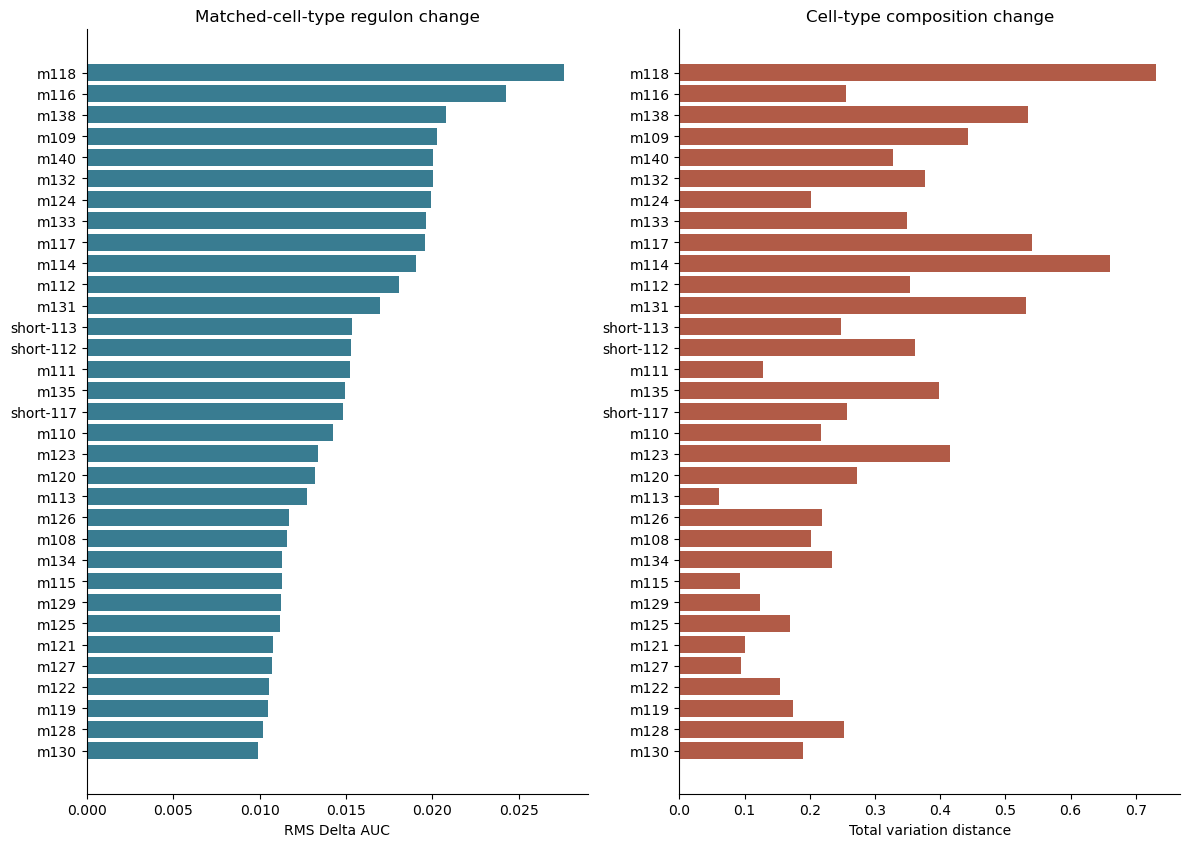

Main plot drug selection: regulon_rms_delta ; drugs: ['m118', 'm116', 'm138', 'm109', 'm140', 'm132']


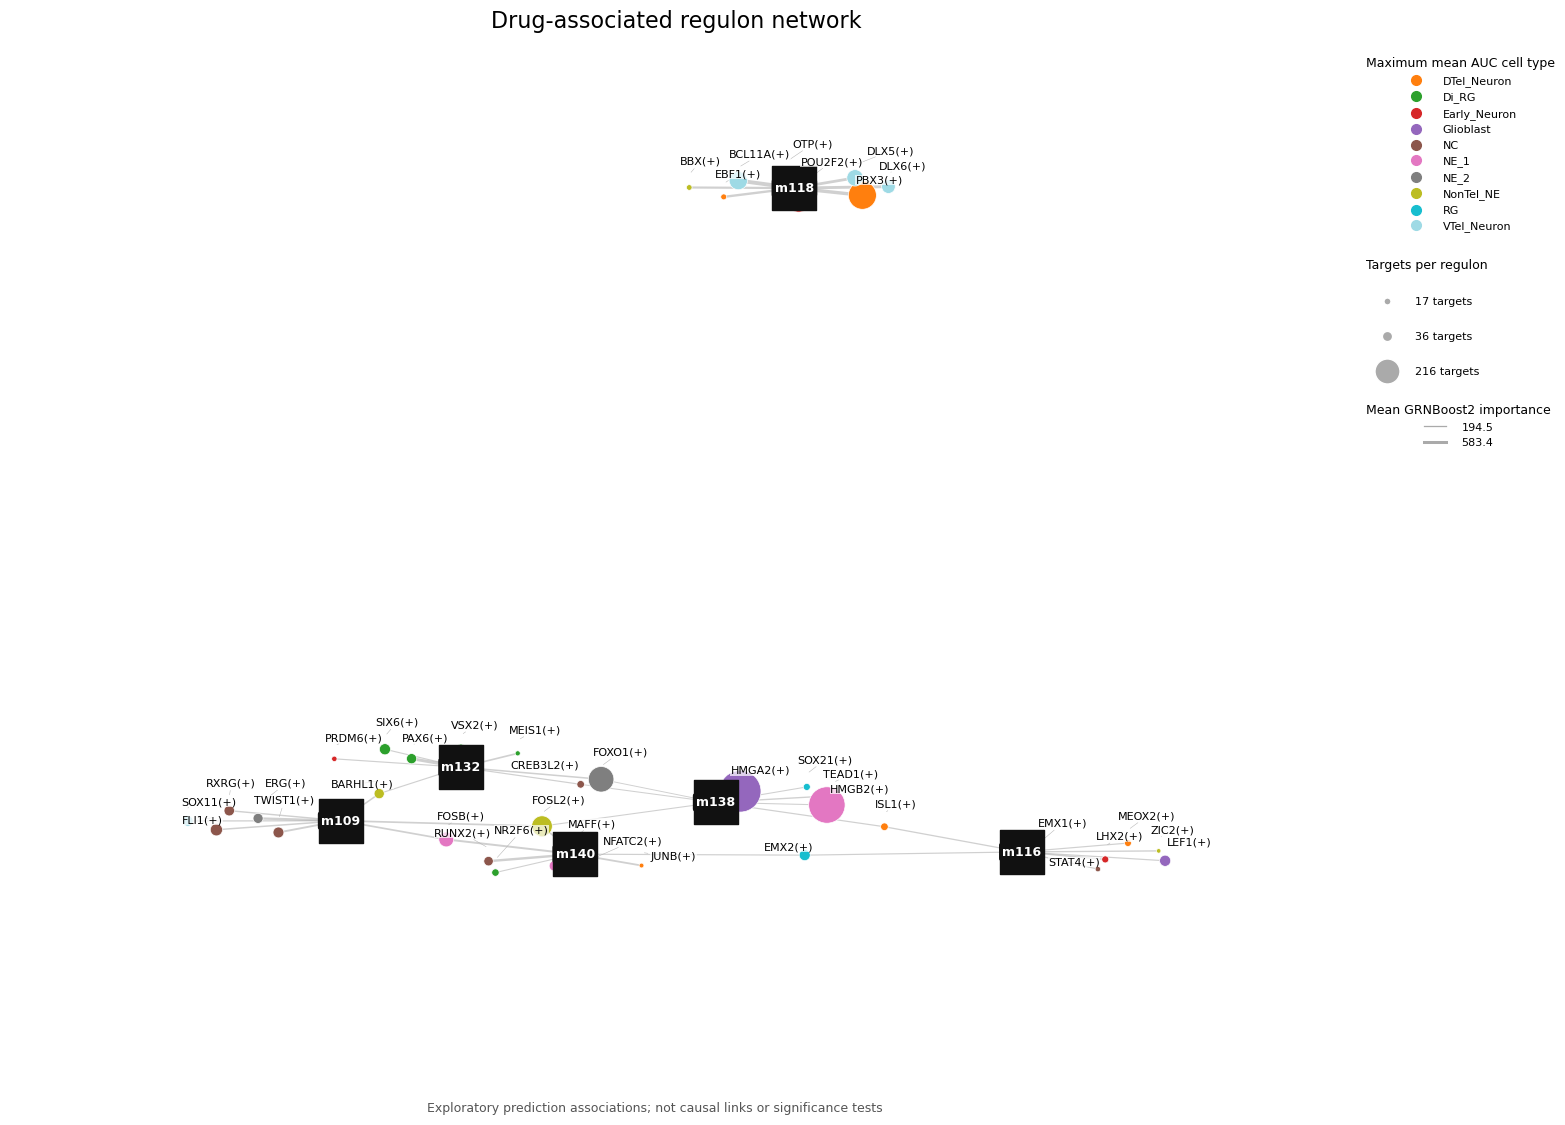

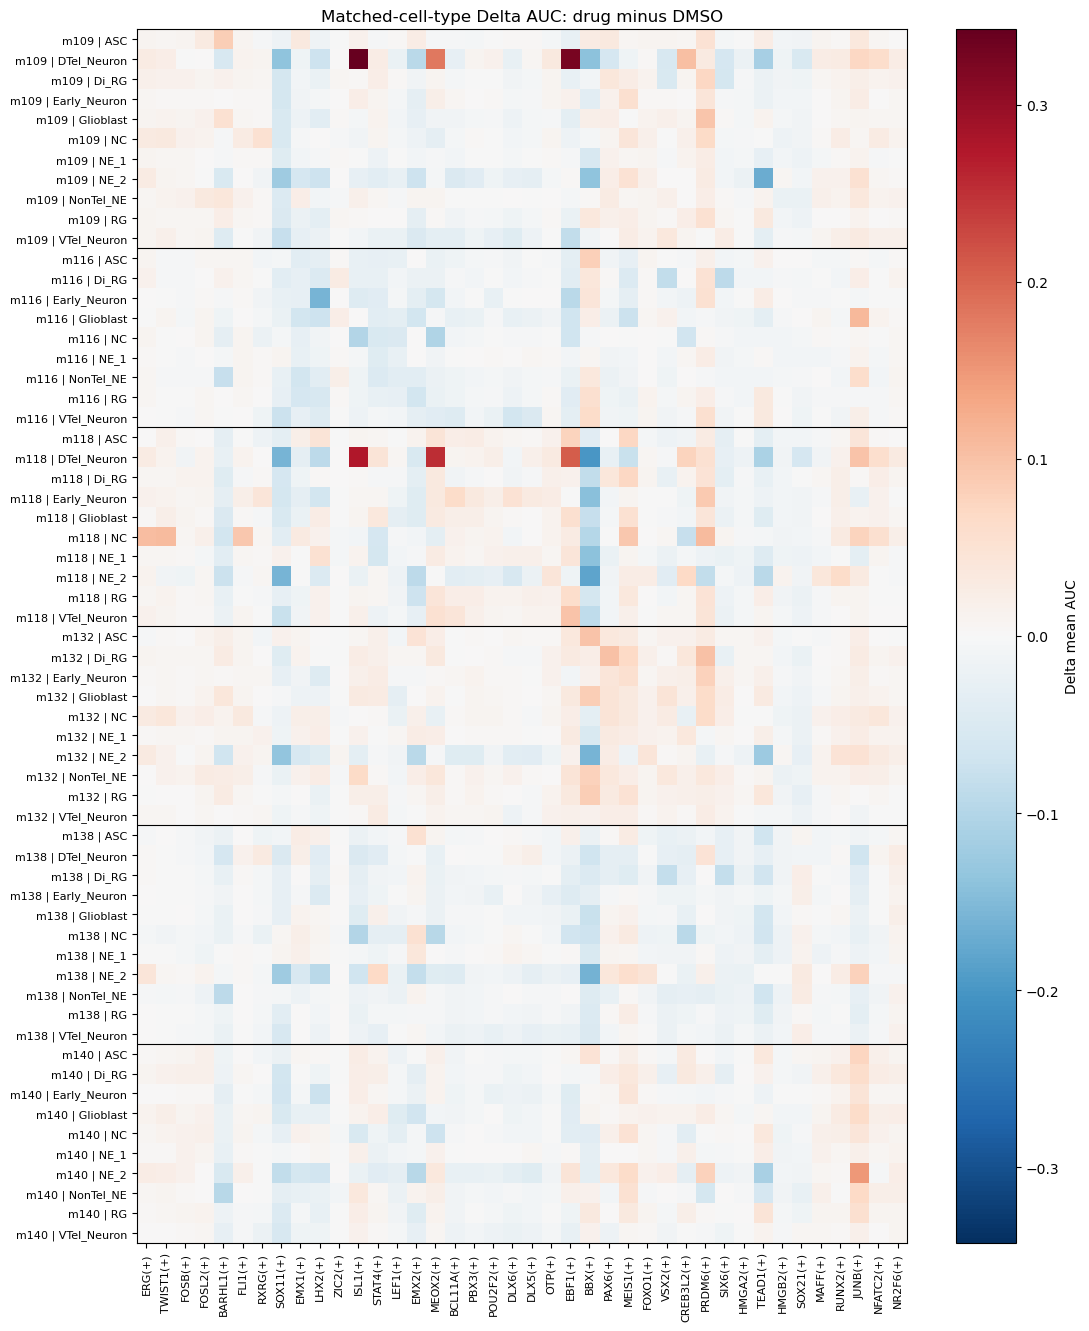

No displayed associations for: ['m119', 'm122', 'm130']


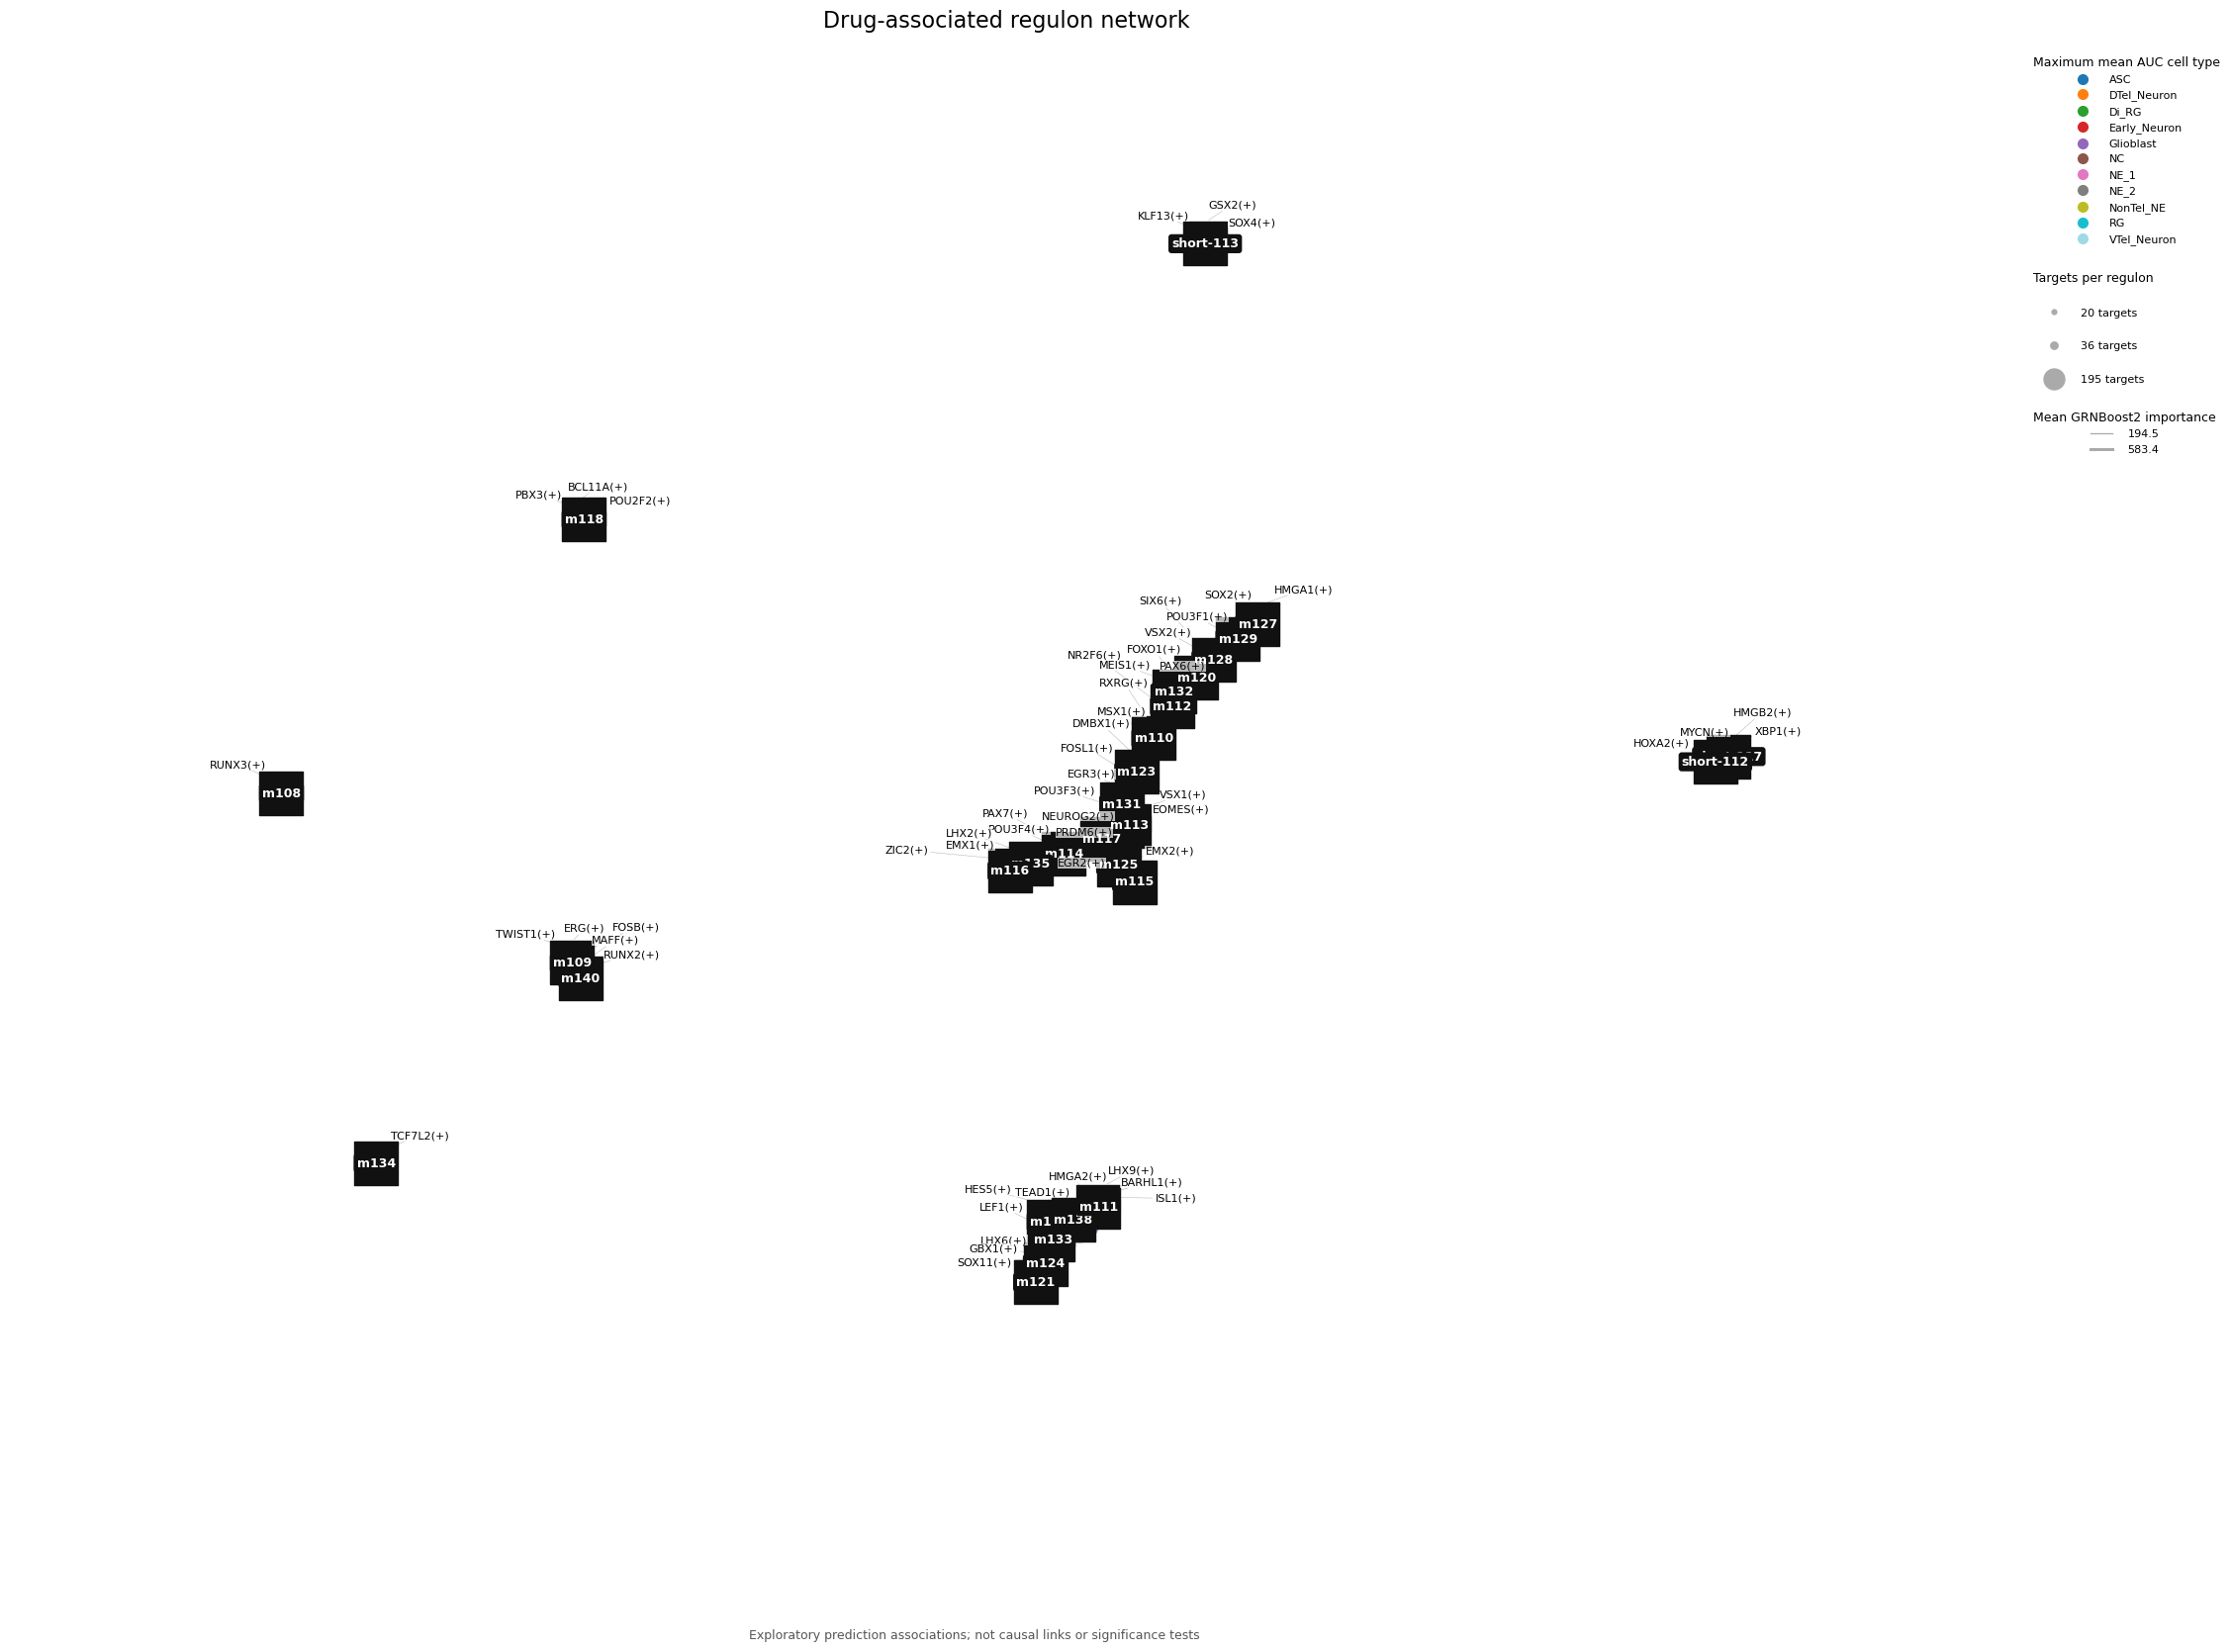

In [11]:
fig_impact = plot_impact(impact_ranking, CFG)
plt.show()
if CFG["plot_drugs_override"] is None:
    plot_selection_metric = "regulon_rms_delta" if common_celltypes else "composition_tv"
    plot_drugs = (impact_ranking.drop(index=CFG["control"])
                  .sort_values(plot_selection_metric, ascending=False)
                  .head(CFG["top_drugs_to_plot"]).index.tolist())
else:
    plot_selection_metric = "manual"
    plot_drugs = list(CFG["plot_drugs_override"])
    if set(plot_drugs).difference(DRUGS) or CFG["control"] in plot_drugs:
        raise ValueError("Plot drugs must be analyzed treatments, excluding DMSO")
print("Main plot drug selection:", plot_selection_metric, "; drugs:", plot_drugs)
fig_network, network = plot_association_network(associations, regulon_nodes, plot_drugs, CFG,
                                               "drug_regulon_network_main", CFG["max_edges_per_drug"])
plt.show()
displayed_edges = pd.read_csv(OUT / "drug_regulon_network_main_displayed_edges.csv")
fig_delta = plot_delta_heatmap(delta_auc, displayed_edges, CFG)
plt.show()
if CFG["make_all_drugs_overview"]:
    fig_overview, overview = plot_association_network(
        associations, regulon_nodes, [d for d in DRUGS if d != CFG["control"]], CFG,
        "drug_regulon_network_all_drugs", CFG["overview_edges_per_drug"]
    )
    plt.show()

## 10. Outputs and interpretation checklist

- `drug_regulon_associations.tsv`: uncapped global associations, stability,
  stratified support and DMSO-relative effects.
- `celltype_associations_summary.csv`: stratified associations; consult the
  eligibility table for missing comparisons.
- `regulon_nodes.csv`: exact pooled target counts and fixed cell-type colors.
- `drug_impact_descriptive.csv`: separate activity-RMS and composition-TV scores.
- `mean_auc_combined.csv` / `delta_auc_by_drug_celltype.csv`: reusable mean/effect tables.
- `model_runs/`: fit logs, target-status/versions, requests and complete checkpoints.
- `figures/`: vector PDF plus PNG for ranking, main/overview networks and signed effects.
- `.graphml`: flat-attribute networks for Cytoscape/Gephi, without the pySCENIC
  `export_regulons` frozenset error.

Before interpreting: check low cell counts and coverage, distinguish global-only
from within-cell-type associations, inspect signs, and check stress/toxicity
programs. A large activity shift is not automatically a beneficial drug.
Unknown batch effects cannot be controlled here. Do not label repeat-seed
stability, cell resampling or cell-level models as biological significance.

In [ ]:
save_json({"config": CFG, "analyzed_drugs": DRUGS, "common_ranking_celltypes": common_celltypes,
           "cells": len(auc_all), "regulons": auc_all.shape[1],
           "stable_global_edges": int(associations["selected"].sum()),
           "plot_drugs": plot_drugs, "plot_selection_metric": plot_selection_metric,
           "display_eligible_edges": int(associations["display_eligible"].sum()),
           "completed": True}, OUT / "analysis_complete.json")
print("Outputs:", OUT)
print("Figures:", OUT / "figures")
print("No source Loom, AUC, regulon or Snakefile was modified.")